# 07 Reliability and myth busting

**Objective.** Test what repeats, quantify ranking uncertainty and check folklore against the data.

**Inputs.** reliability/output tables written by uncertainty, consistency, myths and robustness modules.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from common import style
from common.io import read_parquet, read_table
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
%matplotlib inline

## Step 1. Split-half reliability of level and pressure gap

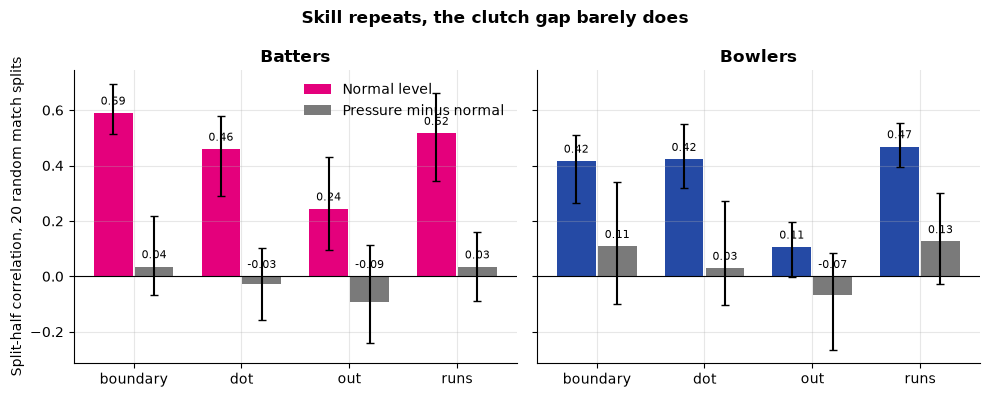

,role,metric_basis,component,kind,r_mean,r_lo,r_hi,players
8,bat,resid,boundary,delta,0.035,-0.066,0.218,81.0
9,bat,resid,boundary,level,0.590,0.514,0.696,81.0
10,bat,resid,dot,delta,-0.028,-0.158,0.102,81.0
11,bat,resid,dot,level,0.460,0.290,0.578,81.0
12,bat,resid,out,delta,-0.094,-0.241,0.113,81.0
13,bat,resid,out,level,0.244,0.096,0.431,81.0
14,bat,resid,runs,delta,0.035,-0.088,0.159,81.0
15,bat,resid,runs,level,0.517,0.345,0.663,81.0
24,bowl,resid,boundary,delta,0.108,-0.099,0.339,91.9
25,bowl,resid,boundary,level,0.416,0.265,0.510,91.9


In [2]:
from reliability import plots as p4
p4.split_half(); plt.show()
read_table("reliability", "split_half_summary.csv").query("metric_basis == 'resid'").round(3)

## Step 2. Raw rate split-half on raw rates

In [3]:
read_table("reliability", "split_half_summary.csv").query("metric_basis == 'raw'").round(3)

,role,metric_basis,component,kind,r_mean,r_lo,r_hi,players
0,bat,raw,boundary,delta,-0.009,-0.167,0.243,81.0
1,bat,raw,boundary,level,0.683,0.573,0.784,81.0
2,bat,raw,dot,delta,0.028,-0.145,0.175,81.0
3,bat,raw,dot,level,0.572,0.399,0.682,81.0
4,bat,raw,out,delta,-0.059,-0.214,0.178,81.0
5,bat,raw,out,level,0.296,0.142,0.488,81.0
6,bat,raw,runs,delta,0.023,-0.090,0.149,81.0
7,bat,raw,runs,level,0.582,0.477,0.736,81.0
16,bowl,raw,boundary,delta,0.127,-0.053,0.348,91.9
17,bowl,raw,boundary,level,0.635,0.543,0.700,91.9


## Step 3. Dot-ball streaks and wickets, by phase

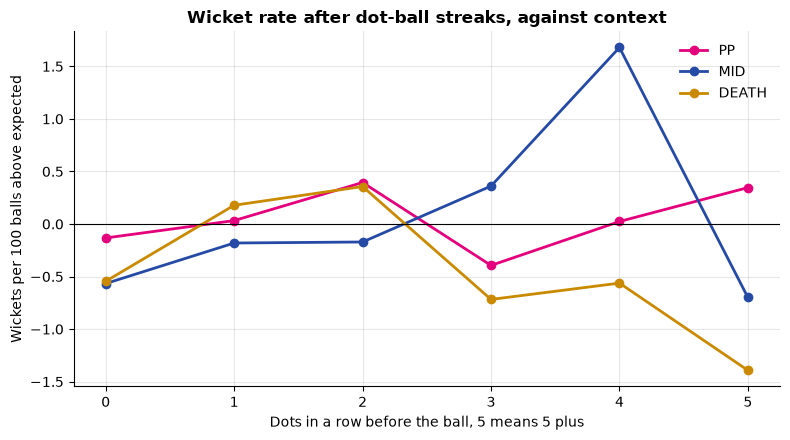

,phase,slope_per_dot,approx_se
0,DEATH,0.001883,0.001690
1,MID,0.002686,0.001373
2,PP,0.000776,0.000660


In [4]:
p4.dot_streak(); plt.show()
read_table("reliability", "myth_dot_streak_slope.csv")

## Step 4. Tight over and next-over wickets

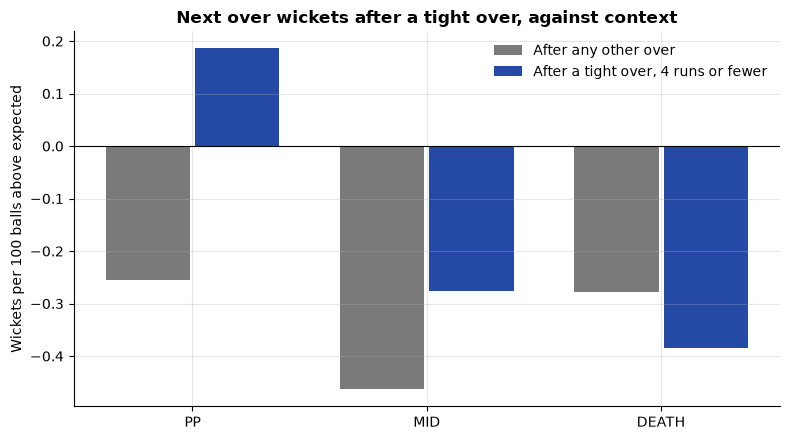

,phase,tight,overs,wkts_next,expected_next,balls,wicket_rate_next,excess_per_100
0,DEATH,False,4650,2256,2330.9530,26958,0.0837,-0.2780
1,DEATH,True,859,392,410.8572,4895,0.0801,-0.3852
2,MID,False,11016,3286,3591.2051,65878,0.0499,-0.4633
3,MID,True,3355,955,1010.3309,20052,0.0476,-0.2759
4,PP,False,7580,1986,2101.8744,45467,0.0437,-0.2549
5,PP,True,2196,604,579.4844,13176,0.0458,0.1861


In [5]:
p4.tight_over(); plt.show()
read_table("reliability", "myth_tight_over.csv").round(4)

## Step 5. Bounce-back, raw against context-controlled

In [6]:
read_table("player_insights", "e1_bounce_back_league.csv").round(4)

,after_bnd,balls,boundary_rate,expected_boundary,runs,expected_runs
0,False,143983,0.1785,0.1716,1.3606,1.3609
1,True,32541,0.2268,0.2057,1.5836,1.5145


## Step 6. Bootstrap rank intervals

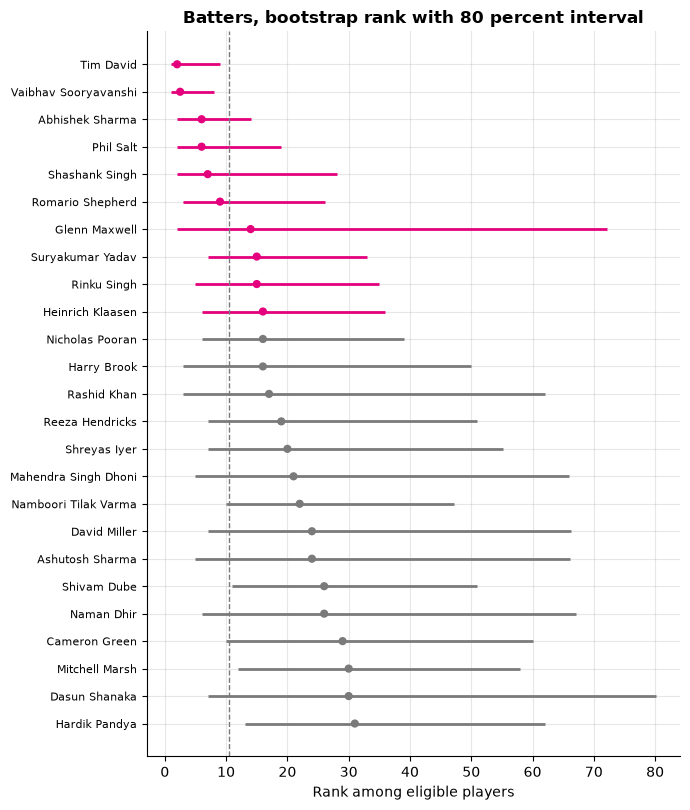

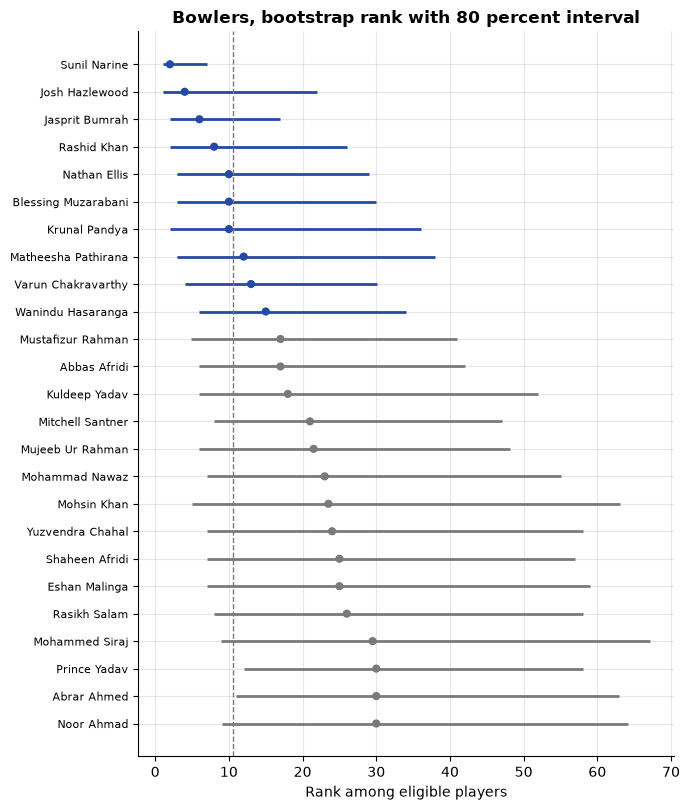

In [7]:
p4.rank_forest("bat"); plt.show()
p4.rank_forest("bowl"); plt.show()

## Step 7. Consistency metrics for the leading players

In [8]:
from reliability.uncertainty import final_order
final_order("bowl").head(10)[["player_name", "qual_matches", "consistency_index", "floor", "median_match"]].round(2)

,player_name,qual_matches,consistency_index,floor,median_match
0,Sunil Narine,19,0.79,-10.73,11.43
1,Josh Hazlewood,24,0.67,-69.51,23.83
2,Jasprit Bumrah,25,0.52,-86.24,1.64
3,Rashid Khan,30,0.60,-46.99,1.35
4,Nathan Ellis,16,0.62,-71.84,11.73
5,Blessing Muzarabani,16,0.44,-85.00,-1.85
6,Krunal Pandya,15,0.67,-16.73,18.40
7,Matheesha Pathirana,18,0.56,-73.81,9.69
8,Varun Chakravarthy,28,0.71,-48.21,18.83
9,Wanindu Hasaranga,25,0.40,-39.50,-6.12


## Step 8. Robustness heatmap

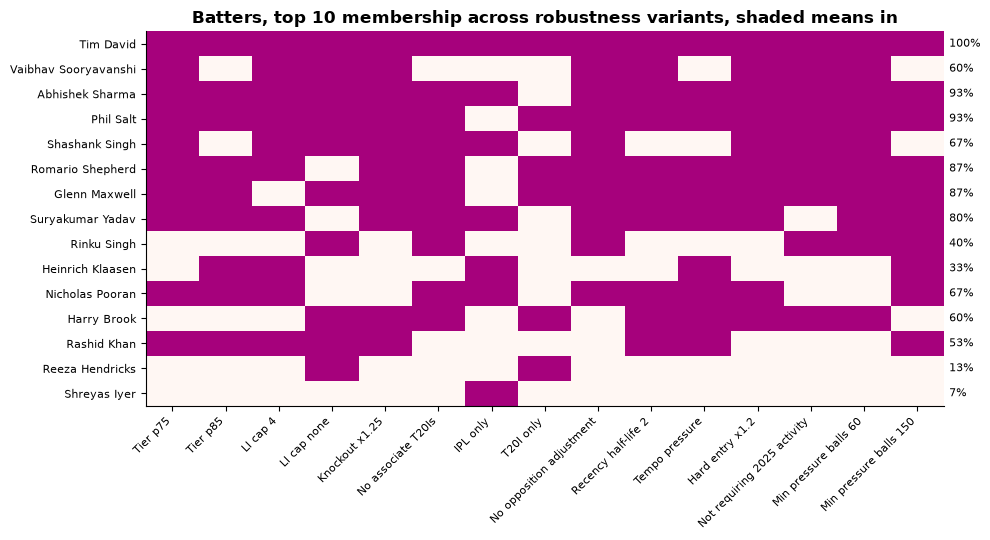

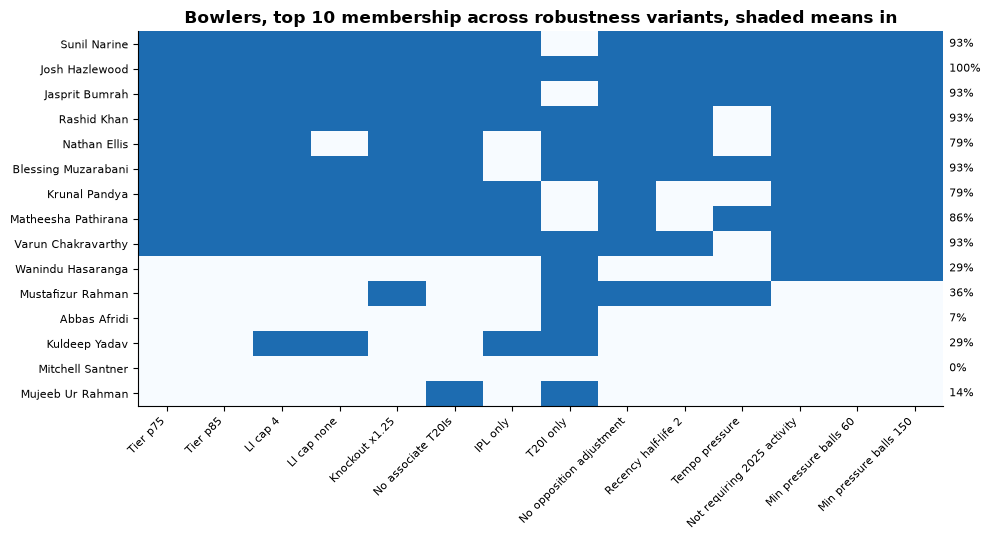

,role,alternative,spearman,players
0,bat,Raw pressure strike rate,0.619,114
1,bat,No opposition adjustment,0.981,114
2,bat,IPL only,0.750,92
3,bowl,Raw pressure economy,0.335,113
4,bowl,No opposition adjustment,0.987,113
5,bowl,IPL only,0.730,91


In [9]:
p4.robustness_heatmap("bat"); plt.show()
p4.robustness_heatmap("bowl"); plt.show()
read_table("reliability", "method_agreement.csv").round(3)

## Key findings

In [10]:
s = read_table("reliability", "split_half_summary.csv").query("metric_basis == 'resid'").set_index(["role", "component", "kind"])["r_mean"]
sl = read_table("reliability", "myth_dot_streak_slope.csv")
bb = read_table("player_insights", "e1_bounce_back_league.csv").set_index("after_bnd")
display(Markdown(f'''
- Batter boundary skill repeats at r {s[("bat", "boundary", "level")]:.2f}, the pressure gap at r {s[("bat", "boundary", "delta")]:.2f}. Runs per ball {s[("bat", "runs", "level")]:.2f} against {s[("bat", "runs", "delta")]:.2f}.
- Bowler boundary skill r {s[("bowl", "boundary", "level")]:.2f}, gap r {s[("bowl", "boundary", "delta")]:.2f}, bowler wickets barely repeat r {s[("bowl", "out", "level")]:.2f}.
- Dot streak slope at most {100 * sl.slope_per_dot.max():.2f} extra wickets per 100 balls per dot, no material effect.
- After a boundary the next ball goes for four or six {bb.loc[True, "boundary_rate"]:.1%} against {bb.loc[False, "boundary_rate"]:.1%}, but context expects {bb.loc[True, "expected_boundary"]:.1%}, so most of it is the situation.
- What this means for the method, rate the skill shown in high-stakes states and shrink the clutch part hard.
'''))


- Batter boundary skill repeats at r 0.59, the pressure gap at r 0.04. Runs per ball 0.52 against 0.03.
- Bowler boundary skill r 0.42, gap r 0.11, bowler wickets barely repeat r 0.11.
- Dot streak slope at most 0.27 extra wickets per 100 balls per dot, no material effect.
- After a boundary the next ball goes for four or six 22.7% against 17.9%, but context expects 20.6%, so most of it is the situation.
- What this means for the method, rate the skill shown in high-stakes states and shrink the clutch part hard.


## Outputs written

reliability/output, bootstrap parquet files gitignored. Tables split_half_summary, split_half_all, bootstrap_summary, consistency, season_prism, match_contributions, myth_*, robustness, robustness_membership, method_agreement. Figures 07_*.png.